## 1. Training 

In [1]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [2]:
#fix seeds so runs are responsible 
torch.manual_seed(0)
np.random.seed(0)

In [3]:
data = np.load(r'data/train.npz')
X = data['field'][:, None, :].astype(np.float32)
Y = data['target'][:, None, :].astype(np.float32)
print("Data:", X.shape, Y.shape)

Data: (240, 1, 128) (240, 1, 128)


In [4]:
# Trajectory-level split, NOT row-level.
# Row-level would leak: rows t*5..t*5+4 belong to the same trajectory, so
# neighbouring time steps of the same physics would land in both train and val.
# We hold out 10 whole trajectories (50 examples) for validation.
n_traj = 48
perm = np.random.permutation(n_traj)
val_traj = perm[:10]
train_traj = perm[10:]
val_idx = np.concatenate([np.arange(t*5, t*5+5) for t in val_traj])
train_idx = np.concatenate([np.arange(t*5, t*5+5) for t in train_traj])

In [5]:
X_train = torch.tensor(X[train_idx]); Y_train = torch.tensor(Y[train_idx])
X_val   = torch.tensor(X[val_idx]);   Y_val   = torch.tensor(Y[val_idx])

Grid-locked CNN baseline: kernel defined in grid points, not physical distance.
Effective receptive field in physical space shrinks as the grid is refined, so the same weights cannot resolve the same features at higher resolutions.

Architecture: 4 layers, kernel 3, hidden 64, circular padding, residual.
Chosen by ablation over depth {2,4,6,8}, kernel {3,5,7}, width {32,64,128};
selected the smallest config within noise of the best validation loss, refer to ablation.py

In [6]:
class GridLockedCNN(nn.Module):

    def __init__(self, hidden=64, kernel_size=3, num_layers=4):
        super().__init__()
        #Circular padding is chosen since theBurgers domain is periodic. Matches CNN baseline convention in Li et al. 2021 and FNO tutorial.
        layers = [nn.Conv1d(1, hidden, kernel_size,
                            padding=kernel_size // 2,
                            padding_mode='circular'), nn.ReLU()]
        for _ in range(num_layers - 1):
            layers += [nn.Conv1d(hidden, hidden, kernel_size,
                                 padding=kernel_size // 2,
                                 padding_mode='circular'), nn.ReLU()]
        layers.append(nn.Conv1d(hidden, 1, kernel_size,
                                padding=kernel_size // 2,
                                padding_mode='circular'))
        self.net = nn.Sequential(*layers)
# Residual form: predict the update, not the full state.
    # Matches the neural-operator layer structure (Kovachki et al. 2023, eq. 6) and stabilises training on small data.
    def forward(self, u):
        return u + self.net(u)

In [7]:
def relative_l2(pred, target):
    num = torch.norm(pred - target, dim=(1, 2))
    den = torch.norm(target, dim=(1, 2)) + 1e-8
    return (num / den).mean()

In [8]:
model = GridLockedCNN(hidden=64, kernel_size=3, num_layers=4)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=32, shuffle=True)
# Callbacks:
#  early stopping (patience 40): small dataset leads to overfitting risk hence stop  when val loss has not improved for 40 epochs.
#  reduce LR on plateau (patience 20): Adam plateaus on small data; halving the LR escapes shallow minima.
#   best-checkpoint saving: preserve the model with the lowest val loss, not the last-epoch model
best_val = float('inf'); wait = 0; lr_wait = 0
train_hist, val_hist = [], []

In [9]:
for epoch in range(600):
    model.train()
    total = 0.0
    for xb, yb in loader:
        loss = relative_l2(model(xb), yb)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total += loss.item() * len(xb)
    tl = total / len(X_train)

    model.eval()
    with torch.no_grad():
        vl = relative_l2(model(X_val), Y_val).item()

    train_hist.append(tl); val_hist.append(vl)
    if epoch % 20 == 0:
        print(f"Epoch {epoch:3d}  train={tl:.6f}  val={vl:.6f}")

    if vl < best_val - 1e-6:
        best_val = vl; wait = 0; lr_wait = 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        wait += 1; lr_wait += 1
#Small dataset means risk of overfitting. Early stop protects against it
    if wait >= 40:
        print(f"Early stop at {epoch}. Best val = {best_val:.6f}")
        break
    if lr_wait >= 20:
        for g in optimizer.param_groups:
            g['lr'] *= 0.5
        print(f"  LR -> {optimizer.param_groups[0]['lr']:.1e}")
        lr_wait = 0
#Preserves best-val model instead of last-epoch model
np.savez('training_history.npz', train=train_hist, val=val_hist, best=best_val)
print(f"Best val = {best_val:.6f}")

Epoch   0  train=0.065765  val=0.039684
Epoch  20  train=0.004405  val=0.004705
Epoch  40  train=0.003053  val=0.003711
Epoch  60  train=0.002965  val=0.003466
Epoch  80  train=0.003427  val=0.003787
  LR -> 5.0e-04
Epoch 100  train=0.002373  val=0.003140
Epoch 120  train=0.001774  val=0.002372
  LR -> 2.5e-04
Epoch 140  train=0.001748  val=0.002432
Epoch 160  train=0.001573  val=0.002264
  LR -> 1.3e-04
Epoch 180  train=0.001601  val=0.002338
Epoch 200  train=0.001526  val=0.002252
  LR -> 6.3e-05
Epoch 220  train=0.001470  val=0.002226
Epoch 240  train=0.001476  val=0.002246
  LR -> 3.1e-05
Epoch 260  train=0.001456  val=0.002218
Epoch 280  train=0.001457  val=0.002210
  LR -> 1.6e-05
Epoch 300  train=0.001449  val=0.002214
  LR -> 7.8e-06
Epoch 320  train=0.001447  val=0.002209
Early stop at 338. Best val = 0.002208
Best val = 0.002208


## 2. Evaluation across resolutions 

In [10]:
import numpy as np
import torch
import torch.nn as nn
# same seeds as training. 
torch.manual_seed(0)
np.random.seed(0)

In [11]:
class GridLockedCNN(nn.Module):
    def __init__(self, hidden=64, kernel_size=5, num_layers=4):
        super().__init__()
        layers = [nn.Conv1d(1, hidden, kernel_size,
                            padding=kernel_size // 2,
                            padding_mode='circular'),
                  nn.ReLU()]
        for _ in range(num_layers - 1):
            layers += [nn.Conv1d(hidden, hidden, kernel_size,
                                 padding=kernel_size // 2,
                                 padding_mode='circular'),
                       nn.ReLU()]
        layers.append(nn.Conv1d(hidden, 1, kernel_size,
                                padding=kernel_size // 2,
                                padding_mode='circular'))
        self.net = nn.Sequential(*layers)

    def forward(self, u):
        return u + self.net(u)

In [12]:
def rel_l2_per_sample(pred, target):
    num = np.linalg.norm((pred - target).reshape(len(pred), -1), axis=1)
    den = np.linalg.norm(target.reshape(len(target), -1), axis=1) + 1e-8
    return num / den

In [13]:
device = 'cpu'
model = GridLockedCNN(hidden=64, kernel_size=3, num_layers=4).to(device)
model.load_state_dict(best_state)
model.eval()
print("Loaded best model from training\n")

Loaded best model from training



In [15]:
# apply the same trained model to all three resolutions, no retraining
results = {}
with torch.no_grad():
    for res in [128, 256, 512]:
        data = np.load(f'data/eval_{res}.npz')
        X = data['field'][:, None, :].astype(np.float32)
        Y = data['target'][:, None, :].astype(np.float32)

        pred = model(torch.tensor(X)).numpy()

        cnn_err = rel_l2_per_sample(pred, Y)
        id_err = rel_l2_per_sample(X, Y)

        results[res] = {'cnn': cnn_err, 'identity': id_err}

        print(f"=== Resolution {res} ===")
        print(f"  CNN mean rel-L2   : {cnn_err.mean():.6f}")
        print(f"  CNN median        : {np.median(cnn_err):.6f}")
        print(f"  Identity baseline : {id_err.mean():.6f}")
        print(f"  Improvement factor: {id_err.mean() / cnn_err.mean():.2f}x")
        print()

=== Resolution 128 ===
  CNN mean rel-L2   : 0.002776
  CNN median        : 0.000608
  Identity baseline : 0.032534
  Improvement factor: 11.72x

=== Resolution 256 ===
  CNN mean rel-L2   : 0.017335
  CNN median        : 0.008578
  Identity baseline : 0.032549
  Improvement factor: 1.88x

=== Resolution 512 ===
  CNN mean rel-L2   : 0.025076
  CNN median        : 0.012638
  Identity baseline : 0.032552
  Improvement factor: 1.30x



In [16]:
e128 = results[128]['cnn'].mean()
e256 = results[256]['cnn'].mean()
e512 = results[512]['cnn'].mean()

Growth ratio = error at higher resolution / error at training resolution.
Ratio ~1 means resolution-invariant; ratio is 1 means the model degrades, which is exactly what we expect from a grid-locked CNN.

In [17]:
print("=== Error Growth ===")
print(f"  Growth 128 -> 256: {e256/e128:.2f}x")
print(f"  Growth 128 -> 512: {e512/e128:.2f}x")

=== Error Growth ===
  Growth 128 -> 256: 6.25x
  Growth 128 -> 512: 9.03x


In [18]:
# per-example errors for the buckets 
np.savez('cnn_errors.npz',
         err_128=results[128]['cnn'],
         err_256=results[256]['cnn'],
         err_512=results[512]['cnn'],
         id_128=results[128]['identity'],
         id_256=results[256]['identity'],
         id_512=results[512]['identity'])
print("\nSaved per-example errors to cnn_errors.npz")


Saved per-example errors to cnn_errors.npz


## 3. Architecture ablation (`ablation`)

In [19]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import json

In [20]:
# Same seeds as training so the trajectory split is identical for every config
torch.manual_seed(0)
np.random.seed(0)

In [21]:
data = np.load(r'data/train.npz')
X = data['field'][:, None, :].astype(np.float32)
Y = data['target'][:, None, :].astype(np.float32)
print("Data:", X.shape, Y.shape)

Data: (240, 1, 128) (240, 1, 128)


In [22]:
# Trajectory-level split: rows t*5..t*5+4 form one trajectory, so row-level splitting would leak nearby time steps into validation.
n_traj = 48
perm = np.random.permutation(n_traj)
val_traj = perm[:10]
train_traj = perm[10:]
val_idx = np.concatenate([np.arange(t*5, t*5+5) for t in val_traj])
train_idx = np.concatenate([np.arange(t*5, t*5+5) for t in train_traj])

In [23]:
X_train = torch.tensor(X[train_idx])
Y_train = torch.tensor(Y[train_idx])
X_val   = torch.tensor(X[val_idx])
Y_val   = torch.tensor(Y[val_idx])
print(f"Train: {len(X_train)}  Val: {len(X_val)}")

Train: 190  Val: 50


In [24]:
class GridLockedCNN(nn.Module):
    def __init__(self, hidden=64, kernel_size=5, num_layers=4):
        super().__init__()
        layers = [nn.Conv1d(1, hidden, kernel_size,
                            padding=kernel_size // 2,
                            padding_mode='circular'),
                  nn.ReLU()]
        for _ in range(num_layers - 1):
            layers += [nn.Conv1d(hidden, hidden, kernel_size,
                                 padding=kernel_size // 2,
                                 padding_mode='circular'),
                       nn.ReLU()]
        layers.append(nn.Conv1d(hidden, 1, kernel_size,
                                padding=kernel_size // 2,
                                padding_mode='circular'))
        self.net = nn.Sequential(*layers)

    def forward(self, u):
        return u + self.net(u)

In [25]:
def relative_l2(pred, target):
    num = torch.norm(pred - target, dim=(1, 2))
    den = torch.norm(target, dim=(1, 2)) + 1e-8
    return (num / den).mean()

In [26]:
def train_config(hidden, kernel_size, num_layers, max_epochs=400, patience=40, seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = GridLockedCNN(hidden, kernel_size, num_layers)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=32, shuffle=True)

    best_val = float('inf')
    wait = 0
    lr_wait = 0
    best_state = None
    history = {'train': [], 'val': []}

    for epoch in range(max_epochs):
        # train
        model.train()
        total = 0.0
        for xb, yb in loader:
            loss = relative_l2(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(xb)
        train_loss = total / len(X_train)

        # validate
        model.eval()
        with torch.no_grad():
            val_loss = relative_l2(model(X_val), Y_val).item()

        history['train'].append(train_loss)
        history['val'].append(val_loss)

        # callbacks
        if val_loss < best_val - 1e-6:
            best_val = val_loss
            wait = 0
            lr_wait = 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            lr_wait += 1

        if wait >= patience:
            break
        if lr_wait >= 20:
            for g in optimizer.param_groups:
                g['lr'] *= 0.5
            lr_wait = 0

    n_params = sum(p.numel() for p in model.parameters())
    return best_val, n_params, history

In [27]:
# 8 configs covering the three main architecture hyperparameters:
#   depth  : 2, 4, 6, 8
#   kernel : 3, 5, 7
#   width  : 32, 64, 128
# Standard ablation range for a small CNN
configs = [
    {'hidden': 64,  'kernel_size': 5, 'num_layers': 2},
    {'hidden': 64,  'kernel_size': 5, 'num_layers': 4},   # baseline
    {'hidden': 64,  'kernel_size': 5, 'num_layers': 6},
    {'hidden': 64,  'kernel_size': 5, 'num_layers': 8},
    {'hidden': 64,  'kernel_size': 3, 'num_layers': 4},
    {'hidden': 64,  'kernel_size': 7, 'num_layers': 4},
    {'hidden': 32,  'kernel_size': 5, 'num_layers': 4},
    {'hidden': 128, 'kernel_size': 5, 'num_layers': 4},
]

In [28]:
results = []
for cfg in configs:
    print(f"\n--- {cfg} ---")
    val, params, _ = train_config(**cfg)
    results.append({**cfg, 'val': val, 'params': params})
    print(f"  best val = {val:.6f}   params = {params:,}")


--- {'hidden': 64, 'kernel_size': 5, 'num_layers': 2} ---
  best val = 0.002573   params = 21,249

--- {'hidden': 64, 'kernel_size': 5, 'num_layers': 4} ---
  best val = 0.002305   params = 62,337

--- {'hidden': 64, 'kernel_size': 5, 'num_layers': 6} ---
  best val = 0.002185   params = 103,425

--- {'hidden': 64, 'kernel_size': 5, 'num_layers': 8} ---
  best val = 0.002488   params = 144,513

--- {'hidden': 64, 'kernel_size': 3, 'num_layers': 4} ---
  best val = 0.002208   params = 37,505

--- {'hidden': 64, 'kernel_size': 7, 'num_layers': 4} ---
  best val = 0.002448   params = 87,169

--- {'hidden': 32, 'kernel_size': 5, 'num_layers': 4} ---
  best val = 0.002436   params = 15,809

--- {'hidden': 128, 'kernel_size': 5, 'num_layers': 4} ---
  best val = 0.002149   params = 247,553


In [29]:
print("\n=== ABLATION SUMMARY ===")
print(f"{'layers':>6} {'kernel':>7} {'hidden':>7} {'params':>10} {'best val':>12}")
for r in sorted(results, key=lambda r: r['val']):
    print(f"{r['num_layers']:>6} {r['kernel_size']:>7} {r['hidden']:>7} "
          f"{r['params']:>10,} {r['val']:>12.6f}")


=== ABLATION SUMMARY ===
layers  kernel  hidden     params     best val
     4       5     128    247,553     0.002149
     6       5      64    103,425     0.002185
     4       3      64     37,505     0.002208
     4       5      64     62,337     0.002305
     4       5      32     15,809     0.002436
     4       7      64     87,169     0.002448
     8       5      64    144,513     0.002488
     2       5      64     21,249     0.002573


In [30]:
with open('ablation_results.json', 'w') as f:
    json.dump(results, f, indent=2)
print("\nSaved ablation_results.json")


Saved ablation_results.json


In [31]:
# Selection rule: pick by validation loss ONLY. Choosing by eval-256/512 error would tune to the test metric and make the subsequent "CNN degrades at higher resolution" finding meaningless  it would be a product of our selection, not of the architecture
# Tie-break: if the top configs are within noise of each other (which they are here, given only 10 validation trajectories), prefer the smaller model to reduce overfitting risk.
best = min(results, key=lambda r: r['val'])
print(f"\nBest config: {best}")


Best config: {'hidden': 128, 'kernel_size': 5, 'num_layers': 4, 'val': 0.0021488515194505453, 'params': 247553}


## 4. Training history plots (`plot_history`)

In [32]:
import numpy as np
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

In [33]:
hist = np.load('training_history.npz')
train = hist['train']
val = hist['val']
best = float(hist['best'])
identity = 0.032534
epochs = np.arange(len(train))

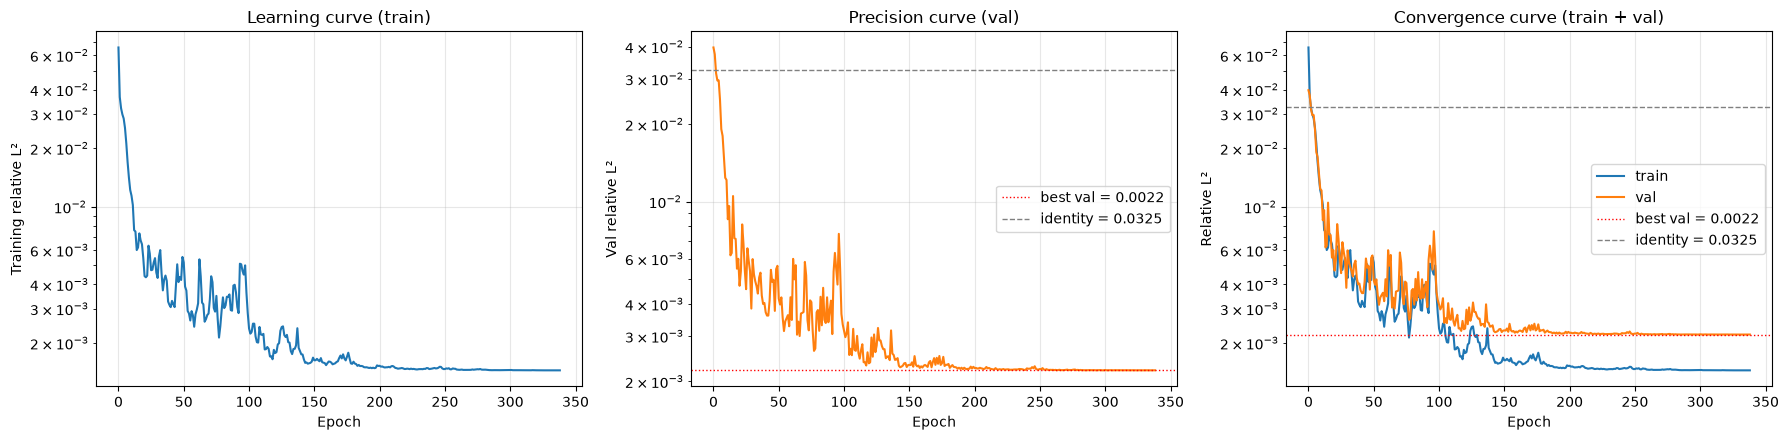

In [34]:
# 3-panel figure: learning | precision | convergence
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# ---- Panel 1: Learning curve (training loss only) ----
axes[0].plot(epochs, train, color='C0', linewidth=1.5)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Training relative L²')
axes[0].set_yscale('log')
axes[0].set_title('Learning curve (train)')
axes[0].grid(True, alpha=0.3)

# ---- Panel 2: Precision curve (validation loss only) ----
axes[1].plot(epochs, val, color='C1', linewidth=1.5)
axes[1].axhline(best, color='red', linestyle=':', linewidth=1,
                label=f'best val = {best:.4f}')
axes[1].axhline(identity, color='gray', linestyle='--', linewidth=1,
                label=f'identity = {identity:.4f}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Val relative L²')
axes[1].set_yscale('log')
axes[1].set_title('Precision curve (val)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# ---- Panel 3: Convergence curve (train + val together) ----
axes[2].plot(epochs, train, label='train', color='C0', linewidth=1.5)
axes[2].plot(epochs, val, label='val', color='C1', linewidth=1.5)
axes[2].axhline(best, color='red', linestyle=':', linewidth=1,
                label=f'best val = {best:.4f}')
axes[2].axhline(identity, color='gray', linestyle='--', linewidth=1,
                label=f'identity = {identity:.4f}')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Relative L²')
axes[2].set_yscale('log')
axes[2].set_title('Convergence curve (train + val)')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Evaluation plots (`plot_eval`)

In [35]:
import numpy as np
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

In [36]:
errs = np.load('cnn_errors.npz')
e128, e256, e512 = errs['err_128'].mean(), errs['err_256'].mean(), errs['err_512'].mean()
i128, i256, i512 = errs['id_128'].mean(), errs['id_256'].mean(), errs['id_512'].mean()

In [38]:
torch.save({'state': best_state, 'config': dict(hidden=64, kernel_size=3, num_layers=4)}, 'cnn_k3_best.pt')

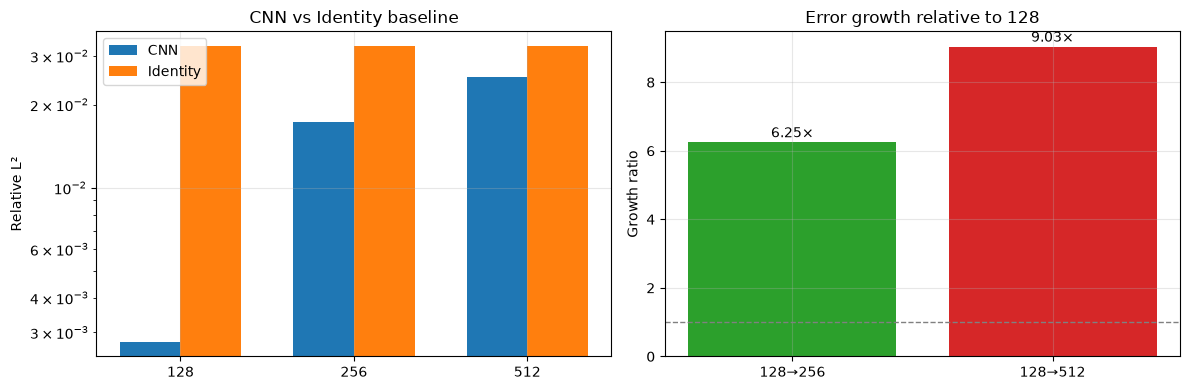

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

x = np.arange(3); w = 0.35
axes[0].bar(x - w/2, [e128, e256, e512], w, label='CNN')
axes[0].bar(x + w/2, [i128, i256, i512], w, label='Identity')
axes[0].set_xticks(x); axes[0].set_xticklabels(['128', '256', '512'])
axes[0].set_ylabel('Relative L²'); axes[0].set_yscale('log')
axes[0].set_title('CNN vs Identity baseline'); axes[0].legend()
axes[0].grid(True, alpha=0.3)

g256, g512 = e256/e128, e512/e128
axes[1].bar(['128→256', '128→512'], [g256, g512], color=['C2', 'C3'])
axes[1].axhline(1.0, color='gray', linestyle='--', linewidth=1)
axes[1].set_ylabel('Growth ratio')
axes[1].set_title('Error growth relative to 128')
for i, v in enumerate([g256, g512]):
    axes[1].text(i, v + 0.15, f'{v:.2f}×', ha='center')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

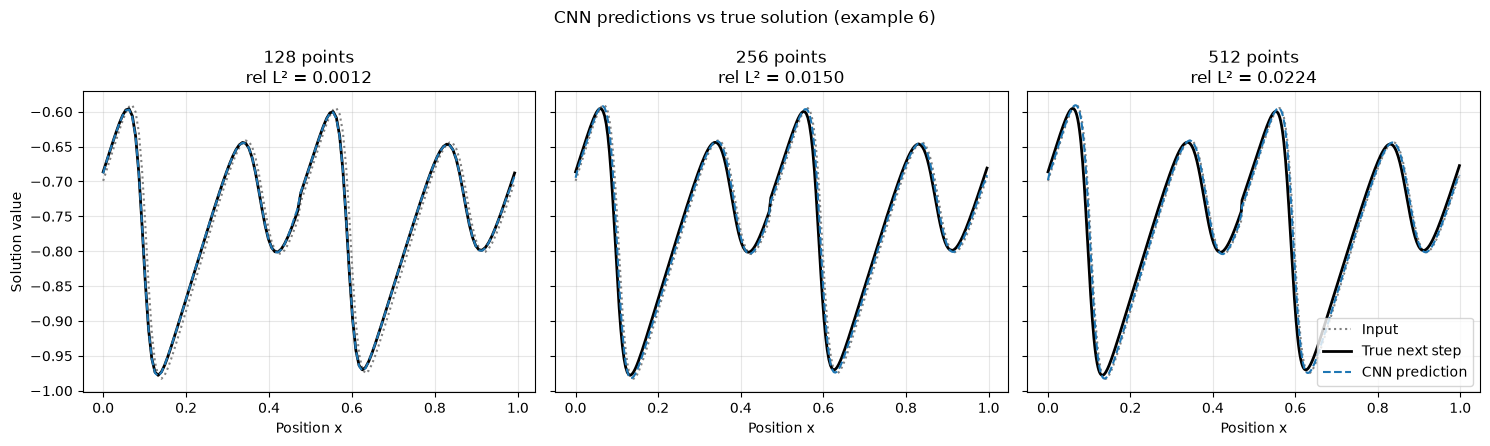

In [41]:
idx = 6   
cnn = GridLockedCNN(hidden=64, kernel_size=3, num_layers=4)
cnn.load_state_dict(best_state)
cnn.eval()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

with torch.no_grad():
    for ax, res in zip(axes, [128, 256, 512]):
        data_e = np.load(f'data/eval_{res}.npz')
        u_in   = data_e['field'][idx].astype(np.float32)
        u_true = data_e['target'][idx].astype(np.float32)

        # Predict this one example: (N,) -> (1, 1, N) -> model -> (N,)
        u_pred = cnn(torch.tensor(u_in[None, None]))[0, 0].numpy()
        err = rel_l2_per_sample(u_pred[None], u_true[None])[0]
        x = np.linspace(0, 1, res, endpoint=False)

        ax.plot(x, u_in,   ':',  color='gray',  linewidth=1.5, label='Input')
        ax.plot(x, u_true, '-',  color='black', linewidth=2,   label='True next step')
        ax.plot(x, u_pred, '--', color='C0',    linewidth=1.5, label='CNN prediction')
        ax.set_title(f"{res} points\nrel L² = {err:.4f}")
        ax.set_xlabel('Position x')
        ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Solution value')
axes[-1].legend(loc='lower right')
fig.suptitle(f'CNN predictions vs true solution (example {idx})')
plt.tight_layout()
plt.show()

# Bucket eval